In [82]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split,cross_val_score)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score,recall_score,f1_score)


In [83]:
data= load_breast_cancer()

In [84]:
df= pd.DataFrame(data.data, columns=data.feature_names)

In [85]:
df['Target']= data.target
print('first 5 row:')
print(df.head())

first 5 row:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0

In [86]:
print('Missing Value:')
print(df.isnull().sum())

Missing Value:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
Target                     0
dtype: int64


In [87]:
X= df.drop('Target',axis=1)
Y= df['Target']

In [88]:
X_train,X_test,Y_train,Y_test=train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify =Y
)

In [89]:
model=RandomForestClassifier( n_estimators=100,
                               max_depth=5,
                               random_state=42,
                              )

In [90]:
model.fit(X_train,Y_train)

RandomForestClassifier(max_depth=5, random_state=42)

In [91]:
y_pred= model.predict(X_test)

In [92]:
accuracy= accuracy_score(Y_test,y_pred)
precision= precision_score(
    Y_test,
    y_pred
)
recall=recall_score(
    Y_test,
    y_pred
)
f1=f1_score(
    Y_test,
    y_pred
)
print('=====================')
print('Random Forest Resuit')
print('=====================')
print('Accuracy:',accuracy)
print('Precision:',precision)
print('Recall;',recall)
print('F1 Score:',f1)


Random Forest Resuit
Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall; 0.9722222222222222
F1 Score: 0.9655172413793104


In [93]:
cv_score= cross_val_score(
    model,
    X,
    Y,
    cv=5
)

In [94]:
print('Cross-validation score:')
print(cv_score.mean())

Cross-validation score:
0.9596180717279925


In [95]:
importance= pd.Series(
    model.feature_importances_,
    index=X.columns
)
importance= importance.sort_values(
    ascending=False
)
print('Top 10 importance Features:')
print(importance.head(10))


Top 10 importance Features:
worst area              0.138294
worst concave points    0.132993
worst radius            0.100805
mean concave points     0.098489
worst perimeter         0.072224
mean perimeter          0.068612
mean radius             0.067465
mean concavity          0.057445
mean area               0.050615
worst concavity         0.031544
dtype: float64


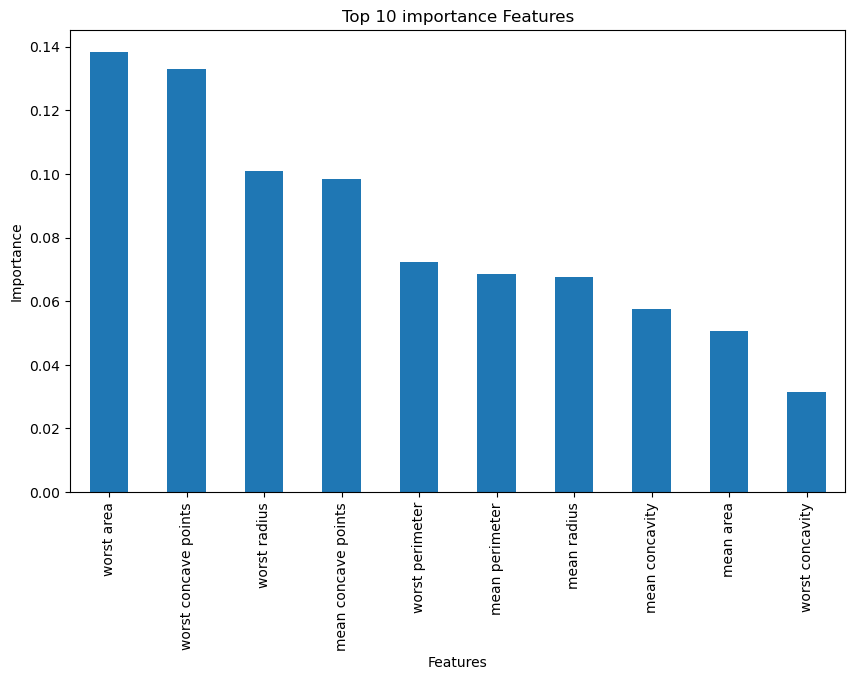

In [105]:
plt.figure(figsize=(10,6))
importance.head(10).plot(
    kind='bar'
)
plt.title('Top 10 importance Features')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()